[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S06/3_Reto/3_Consultar/solucionario/reto_S06.ipynb)

# S06 · Reto «Datos sucios, cliente impaciente» · entrega de referencia

**Equipo:** referencia del docente · **Fecha:** 10/11/2026 · **Datos:** `reservas_sucio.csv` (1545 filas, 18 columnas)

Este cuaderno corre de arriba abajo con *Entorno de ejecución → Reiniciar y ejecutar todo*. Orden: preparación → inventario de defectos → `limpiar_reservas` → partición → *pipeline* y *baseline* → IA responsable → extras → versiones.

In [1]:
#@title ▶ Ejecuta esta celda primero
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

SEMILLA = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

crudo = pd.read_csv(dato("reservas_sucio.csv"))
print(crudo.shape)

(1545, 18)


## 1 · Inventario de defectos

Solo se mira: `crudo` no se modifica nunca.

In [2]:
def resumen_calidad(tabla):
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "distintos": tabla.nunique(),
    })

resumen_calidad(crudo)

,tipo,nulos,pct_nulos,distintos
id_reserva,int64,0,0.00,1500
fecha_reserva,object,0,0.00,753
fecha_llegada,object,0,0.00,677
antelacion_dias,int64,0,0.00,264
noches,int64,0,0.00,17
adultos,float64,46,2.98,4
ninos,int64,0,0.00,4
tipo_habitacion,object,0,0.00,4
regimen,object,61,3.95,4
canal,object,0,0.00,9


In [3]:
print("Filas duplicadas exactas:", crudo.duplicated().sum())
print("Precios escritos con coma:", crudo["precio_noche"].astype(str).str.contains(",").sum())
iso = pd.to_datetime(crudo["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
espanol = pd.to_datetime(crudo["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
print("Fechas ISO:", iso.notna().sum(), "· dd/mm/aaaa:", espanol.notna().sum(), "· sin leer:", (iso.isna() & espanol.isna()).sum())
crudo[["fecha_reserva", "precio_noche"]].head(8)

Filas duplicadas exactas: 45
Precios escritos con coma: 153
Fechas ISO: 1391 · dd/mm/aaaa: 154 · sin leer: 0


,fecha_reserva,precio_noche
0,2025-11-09,84.36
1,19/11/2024,74.14
2,22/01/2025,NaN
3,2025-08-07,93.82
4,2024-03-03,NaN
5,2024-09-20,77.77
6,2024-09-01,81.02
7,02/11/2025,73.2


In [4]:
print(crudo["canal"].value_counts().to_string())
print()
print(crudo["pais_origen"].value_counts().to_string())

canal
web_intermediaria     718
directo               311
agencia               297
empresa                84
WEB_INTERMEDIARIA      34
Web Intermediaria      33
web intermediaria      28
Directo                24
directo                16

pais_origen
ES             351
UK             316
DE             223
otros          145
Nordicos        88
NL              78
IT              78
FR              57
España          26
es              23
uk              23
Reino Unido     22


In [5]:
precio = pd.to_numeric(crudo["precio_noche"].astype(str).str.replace(",", "."), errors="coerce")
print(precio.describe().round(1))
print("Precios <= 0:", (precio <= 0).sum(), "· precios > 1000:", (precio > 1000).sum())
print("Noches <= 0:", (crudo["noches"] <= 0).sum())
print("Antelaciones negativas:", (crudo["antelacion_dias"] < 0).sum())

count    1461.0
mean      129.6
std       518.4
min       -50.0
25%        78.0
50%        93.3
75%       120.0
max      9999.0
Name: precio_noche, dtype: float64
Precios <= 0: 4 · precios > 1000: 4
Noches <= 0: 6
Antelaciones negativas: 5


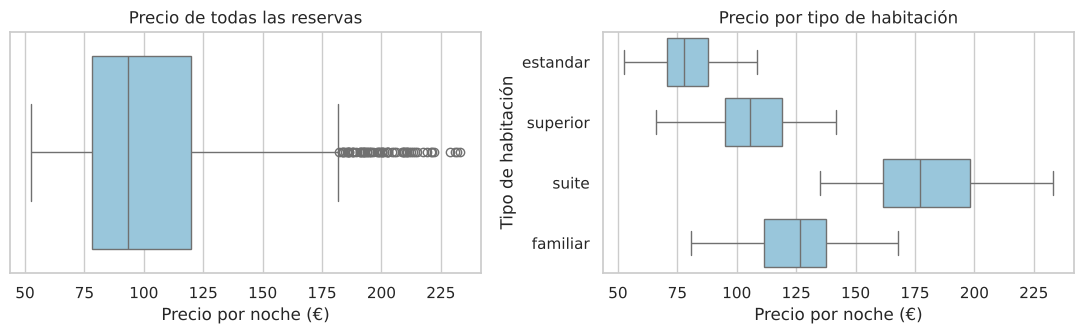

In [6]:
precio_ok = precio[precio.between(1, 1000)]
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=precio_ok, ax=ejes[0], color="#8ecae6")
ejes[0].set(title="Precio de todas las reservas", xlabel="Precio por noche (€)")
sns.boxplot(x=precio_ok, y=crudo.loc[precio_ok.index, "tipo_habitacion"], ax=ejes[1], color="#8ecae6")
ejes[1].set(title="Precio por tipo de habitación", xlabel="Precio por noche (€)", ylabel="Tipo de habitación")
plt.tight_layout()
plt.show()

In [7]:
nulos = crudo.isna().sum()
print(nulos[nulos > 0])
fecha_reserva = iso.fillna(espanol)
fecha_llegada = pd.to_datetime(crudo["fecha_llegada"], format="%Y-%m-%d")
antelacion_calculada = (fecha_llegada - fecha_reserva).dt.days
print("Antelaciones que no cuadran con las fechas:", (antelacion_calculada != crudo["antelacion_dias"]).sum())

adultos          46
regimen          61
pais_origen     115
precio_noche     84
dtype: int64
Antelaciones que no cuadran con las fechas: 5


In [8]:
nulos_pais = int(crudo["pais_origen"].isna().sum())
nulos_regimen = int(crudo["regimen"].isna().sum())
nulos_precio = int(crudo["precio_noche"].isna().sum())

assert nulos_pais == 115 and nulos_regimen == 61 and nulos_precio == 84, "Revisa: usa .isna().sum() sobre crudo"
print("✔ Paso 2 · conteos correctos")

✔ Paso 2 · conteos correctos


## 2 · Limpieza con reglas fijas

`limpiar_reservas` devuelve la tabla limpia y un resumen. No toca `crudo` y no calcula medias ni medianas (eso va en el *pipeline*).

In [9]:
EQUIV_PAIS = {"es": "ES", "españa": "ES", "uk": "UK", "reino unido": "UK", "de": "DE",
              "nl": "NL", "it": "IT", "fr": "FR", "nordicos": "Nordicos", "otros": "otros"}

def limpiar_reservas(tabla):
    """Limpia reservas_sucio.csv con reglas fijas y devuelve (tabla_limpia, resumen).

    No modifica la tabla que recibe: trabaja sobre una copia.
    Solo aplica reglas que no dependen de los datos (no calcula medias ni medianas).
    El resumen cuenta lo que ha cambiado: filas quitadas, valores imposibles pasados a nulo, etc.
    """
    t = tabla.copy()
    resumen = {"filas_antes": len(t)}

    # 1. Duplicados exactos fuera
    t = t.drop_duplicates().reset_index(drop=True)
    resumen["duplicados_quitados"] = resumen["filas_antes"] - len(t)

    # 2. Precio a número
    t["precio_noche"] = pd.to_numeric(t["precio_noche"].astype(str).str.replace(",", "."), errors="coerce")

    # 3. Fechas en dos formatos: lee cada formato por separado y únelos
    iso = pd.to_datetime(t["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
    espanol = pd.to_datetime(t["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
    t["fecha_reserva"] = iso.fillna(espanol)
    t["fecha_llegada"] = pd.to_datetime(t["fecha_llegada"], format="%Y-%m-%d")

    # 4. Categorías
    t["canal"] = t["canal"].str.strip().str.lower().str.replace(" ", "_")
    t["pais_origen"] = t["pais_origen"].str.strip().str.lower().map(EQUIV_PAIS)

    # 5. Valores imposibles a nulo, sin borrar la fila
    nulos_antes = t[["precio_noche", "noches"]].isna().sum().sum()
    t["precio_noche"] = t["precio_noche"].where(t["precio_noche"].between(20, 1000))
    t["noches"] = t["noches"].where(t["noches"].between(1, 60))
    resumen["imposibles_a_nulo"] = int(t[["precio_noche", "noches"]].isna().sum().sum() - nulos_antes)

    # 6. Antelación recalculada desde las fechas
    antelacion_vieja = t["antelacion_dias"]
    t["antelacion_dias"] = (t["fecha_llegada"] - t["fecha_reserva"]).dt.days
    resumen["antelaciones_recalculadas"] = int((t["antelacion_dias"] != antelacion_vieja).sum())

    t["mes_llegada"] = t["fecha_llegada"].dt.month
    resumen["filas_despues"] = len(t)
    return t, resumen

In [10]:
limpia, resumen = limpiar_reservas(crudo)
print(resumen)
print(crudo.shape, limpia.shape)

assert crudo.shape == (1545, 18), "La función no debe modificar el DataFrame original (crudo)"
assert limpia.shape[0] == 1500 and limpia["id_reserva"].is_unique, "Deben quedar 1500 filas sin repetir"
assert limpia["canal"].nunique() == 4 and limpia["pais_origen"].nunique() == 8
assert (limpia["antelacion_dias"] >= 0).all()
print("✔ Paso 3 · limpiar_reservas correcta")

{'filas_antes': 1545, 'duplicados_quitados': 45, 'imposibles_a_nulo': 14, 'antelaciones_recalculadas': 5, 'filas_despues': 1500}
(1545, 18) (1500, 19)
✔ Paso 3 · limpiar_reservas correcta


In [11]:
antes_despues = pd.DataFrame({
    "antes": [len(crudo), crudo.duplicated().sum(), crudo["canal"].nunique(), crudo["pais_origen"].nunique()],
    "después": [len(limpia), limpia.duplicated().sum(), limpia["canal"].nunique(), limpia["pais_origen"].nunique()],
}, index=["filas", "duplicados", "valores distintos de canal", "valores distintos de país"])
display(antes_despues)

nulos = pd.DataFrame({"antes": crudo.isna().sum(), "después": limpia[crudo.columns].isna().sum()})
display(nulos[nulos.sum(axis=1) > 0])
print(limpia["fecha_reserva"].min().date(), limpia["fecha_reserva"].max().date())

,antes,después
filas,1545,1500
duplicados,45,0
valores distintos de canal,9,4
valores distintos de país,12,8


,antes,después
noches,0,6
adultos,46,46
regimen,61,59
pais_origen,115,112
precio_noche,84,87


2024-01-01 2025-12-30


## 3 · Partición *train/test*

Se parte **antes** de ajustar nada; `stratify=y` mantiene la proporción de canceladas (0,47).

In [12]:
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "mes_llegada"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X = limpia[columnas_num + columnas_cat]
y = limpia["cancelada"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

assert X_train.shape == (1200, 15) and X_test.shape == (300, 15), "Deben salir 1200 y 300 filas"
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))
print("✔ Paso 3 · partición correcta")

(1200, 15) (300, 15) 0.471 0.47
✔ Paso 3 · partición correcta


## 4 · *Pipeline*, *baseline* y validación cruzada

Imputar, escalar y codificar se ajusta **solo con *train***, dentro del `Pipeline`.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesado = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("esc", StandardScaler())]), columnas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), columnas_cat),
])

matriz = preprocesado.fit_transform(X_train)     # fit solo con train
assert matriz.shape == (1200, 34), "Deben salir 34 columnas tras el preprocesado"
print(X_train.shape, "→", matriz.shape)
print("✔ Paso 4 · preprocesado correcto")

(1200, 15) → (1200, 34)
✔ Paso 4 · preprocesado correcto


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

modelo = Pipeline([("prep", preprocesado), ("clf", LogisticRegression(max_iter=1000))])
tonto = Pipeline([("prep", preprocesado), ("clf", DummyClassifier(strategy="prior"))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
auc_tonto = cross_val_score(tonto, X_train, y_train, cv=cv, scoring="roc_auc")
auc_modelo = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")

resultados = pd.DataFrame({
    "media": [auc_tonto.mean(), auc_modelo.mean()],
    "desviación": [auc_tonto.std(), auc_modelo.std()],
}, index=["modelo tonto", "regresión logística"]).round(3)
display(resultados)

assert abs(auc_tonto.mean() - 0.5) < 1e-9 and 0.70 < auc_modelo.mean() < 0.82
print("✔ Paso 4 · baseline y validación cruzada correctos")

,media,desviación
modelo tonto,0.500,0.000
regresión logística,0.758,0.025


✔ Paso 4 · baseline y validación cruzada correctos


In [15]:
# Test: se mira UNA vez, al final, con el modelo ya decidido
from sklearn.metrics import roc_auc_score
modelo.fit(X_train, y_train)
auc_test = roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
print(f"AUC en test (una sola vez): {auc_test:.3f}")

AUC en test (una sola vez): 0.752


## 5 · IA responsable: el país de origen

In [16]:
# Riesgo del país de origen: ¿cancelan distinto según el país? ¿cuántos faltan?
print(limpia.groupby("pais_origen")["cancelada"].agg(["mean", "count"]).round(2))
print(limpia["pais_origen"].isna().sum(), round(limpia["pais_origen"].isna().mean(), 3))

             mean  count
pais_origen             
DE           0.49    219
ES           0.45    388
FR           0.46     56
IT           0.60     77
NL           0.37     75
Nordicos     0.47     85
UK           0.48    349
otros        0.43    139
112 0.075


In [17]:
# Medida: el mismo modelo sin pais_origen. ¿Pierde algo?
cat_sin_pais = [c for c in columnas_cat if c != "pais_origen"]
prep_sin = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), columnas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_sin_pais),
])
modelo_sin_pais = Pipeline([("prep", prep_sin), ("clf", LogisticRegression(max_iter=1000))])
auc_sin_pais = cross_val_score(modelo_sin_pais, X_train[columnas_num + cat_sin_pais], y_train, cv=cv, scoring="roc_auc")
print(f"Con país: {auc_modelo.mean():.3f} ± {auc_modelo.std():.3f} · sin país: {auc_sin_pais.mean():.3f} ± {auc_sin_pais.std():.3f}")

Con país: 0.758 ± 0.025 · sin país: 0.759 ± 0.026


**Lectura.** Italia cancela más (0,60 sobre 77 reservas) que Países Bajos (0,37 sobre 75); faltan 112 países (7,5 %) y el imputador pondría `ES`. Quitar `pais_origen` no empeora el modelo (AUC 0,759 con 0,025 de desviación frente a 0,758), así que la recomendación es **no usarlo**.

## 6 · Extras

**A.** Partición temporal: se entrena con el 80 % más antiguo y se evalúa con el 20 % más reciente.

In [18]:
# A · partición temporal
from sklearn.metrics import roc_auc_score
orden = limpia.sort_values("fecha_reserva")
corte = int(len(orden) * 0.8)
X_tr_t, X_te_t = orden[columnas_num + columnas_cat].iloc[:corte], orden[columnas_num + columnas_cat].iloc[corte:]
y_tr_t, y_te_t = orden["cancelada"].iloc[:corte], orden["cancelada"].iloc[corte:]
modelo_t = Pipeline([("prep", preprocesado), ("clf", LogisticRegression(max_iter=1000))])
modelo_t.fit(X_tr_t, y_tr_t)
auc_temporal = round(roc_auc_score(y_te_t, modelo_t.predict_proba(X_te_t)[:, 1]), 3)
print("AUC con partición temporal:", auc_temporal)

AUC con partición temporal: 0.737


**B.** Fuga de datos: lo que «ve» el escalado con solo *train* o con todos los datos.

In [19]:
# B · fuga
media_train = X_train["precio_noche"].mean()
media_todo = X["precio_noche"].mean()
print(f"Media con solo train: {media_train:.2f} · con todos los datos: {media_todo:.2f}")

Media con solo train: 102.68 · con todos los datos: 102.73


Con todos los datos, el escalado ya conoce el *test*: sus números se cuelan en el entrenamiento aunque la diferencia sea pequeña (102,68 frente a 102,73). Por eso todo se ajusta dentro del `Pipeline` y con *train*.

## 7 · Versiones

In [20]:
import sys, sklearn
print("Python", sys.version.split()[0], "· pandas", pd.__version__, "· scikit-learn", sklearn.__version__)

Python 3.13.18 · pandas 2.3.3 · scikit-learn 1.9.1
